## B1. Deskripsi Dataset

Dataset ini bersumber dari UCI Machine Learning Repository (Breast Cancer Wisconsin Diagnostic) yang terdiri dari 569 baris data sampel serta 30 fitur numerik hasil ekstraksi citra digital Fine Needle Aspirate (FNA) massa payudara, dan digunakan untuk mengklasifikasikan diagnosis tumor ke dalam dua kelas variabel target biner, yaitu ganas (malignant, kode 0) atau jinak (benign, kode 1).

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
)

# Set style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

# Load dataset
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['target'] = cancer.target

print(f"Bentuk Dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Bentuk Dataset: 569 baris, 31 kolom


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## B2. Eksplorasi dan Visualisasi Data

Di bawah ini ditampilkan statistik deskriptif dan tiga visualisasi data:
1. **Bar Chart Distribusi Kelas Target** (Melihat keseimbangan kelas).
2. **Box Plot Fitur Numerik per Kelas** (Melihat distribusi fitur berdasarkan kelas target).
3. **Heatmap Korelasi** (Melihat hubungan antarfitur numerik).

=== Statistik Deskriptif (5 Fitur Pertama) ===


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
count,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360
std,3.524049,4.301036,24.298981,351.914129,0.014064
min,6.981000,9.710000,43.790000,143.500000,0.052630
25%,11.700000,16.170000,75.170000,420.300000,0.086370
50%,13.370000,18.840000,86.240000,551.100000,0.095870
75%,15.780000,21.800000,104.100000,782.700000,0.105300
max,28.110000,39.280000,188.500000,2501.000000,0.163400


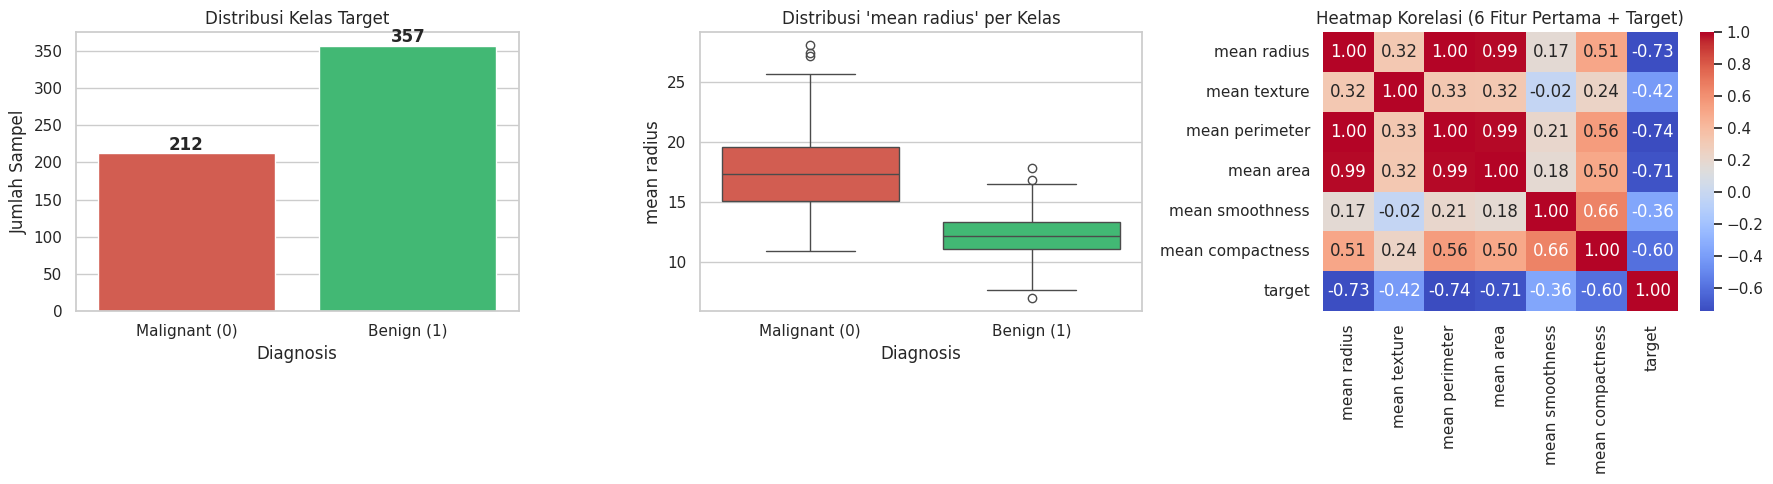

In [17]:
# 1. Statistik Deskriptif
print("=== Statistik Deskriptif (5 Fitur Pertama) ===")
display(df.iloc[:, :5].describe())

# 2. Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Data kelas target
target_counts = df["target"].value_counts().sort_index()

class_counts = pd.DataFrame({
    "Diagnosis": ["Malignant (0)", "Benign (1)"],
    "Jumlah": target_counts.values
})

# a. Bar Chart Distribusi Kelas
sns.barplot(
    data=class_counts,
    x="Diagnosis",
    y="Jumlah",
    hue="Diagnosis",
    palette=["#e74c3c", "#2ecc71"],
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Distribusi Kelas Target")
axes[0].set_ylabel("Jumlah Sampel")

for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 5, str(v), ha="center", fontweight="bold")

# b. Box Plot Fitur Numerik per Kelas
df_plot = df.copy()
df_plot["Diagnosis"] = df_plot["target"].map({
    0: "Malignant (0)",
    1: "Benign (1)"
})

sns.boxplot(
    data=df_plot,
    x="Diagnosis",
    y="mean radius",
    hue="Diagnosis",
    palette=["#e74c3c", "#2ecc71"],
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Distribusi 'mean radius' per Kelas")

# c. Heatmap Korelasi Fitur Terpilih
selected_cols = cancer.feature_names[:6].tolist() + ["target"]
corr_matrix = df[selected_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=axes[2],
    cbar=True
)

axes[2].set_title("Heatmap Korelasi (6 Fitur Pertama + Target)")

plt.tight_layout()
plt.show()

### Temuan dari Visualisasi:
1. **Distribusi Kelas Target:** Kelas `1` (*benign*) berjumlah 357 data (62.7%) dan kelas `0` (*malignant*) berjumlah 212 data (37.3%). Proporsi ini relatif seimbang sehingga tidak terjadi ketimpangan kelas (*extreme class imbalance*) yang parah.
2. **Box Plot (`mean radius`):** Tumor dengan kondisi *malignant* (0) cenderung memiliki rata-rata *radius* yang lebih besar signifikan dibandingkan tumor *benign* (1).
3. **Heatmap Korelasi:** Terdapat korelasi yang sangat kuat antara fitur ukuran fisik sel (seperti `mean radius`, `mean perimeter`, dan `mean area`).

## B3. Preprocessing

1. **Pengecekan Missing Value & Duplikat:** Memastikan data bersih sebelum pemodelan.
2. **Analisis Keseimbangan Kelas:** Rasio kelas adalah 62.7% : 37.3%. Jika kelas sangat tidak seimbang (*imbalanced*), model dapat memprediksi kelas mayoritas secara bias. Penanganannya dapat menggunakan `class_weight='balanced'` pada Logistic Regression atau teknik *resampling* (seperti SMOTE/undersampling).
3. **Fitur Scaling:** Menggunakan `StandardScaler` agar seluruh fitur berada pada skala standar (mean=0, std=1), yang sangat krusial bagi algoritma terkonvergensi seperti Logistic Regression.

In [18]:
# Cek Missing Value dan Duplikat
print("Missing Value:", df.isnull().sum().sum())
print("Jumlah Data Duplikat:", df.duplicated().sum())

# Memisahkan Fitur (X) dan Target (y)
X = df.drop(columns=['target'])
y = df['target']

Missing Value: 0
Jumlah Data Duplikat: 0


## B4. Pemilihan Fitur

Menggunakan metode **`SelectKBest`** dengan statistik uji ANOVA F-value (`f_classif`) untuk memilih **10 fitur terbaik** yang memiliki tingkat diskriminasi paling kuat terhadap kelas target.

In [19]:
selector = SelectKBest(score_func=f_classif, k=10)
X_selected = selector.fit_transform(X, y)

selected_features = X.columns[selector.get_support()].tolist()
print("Fitur Terpilih (Top 10):")
for f in selected_features:
    print(f"- {f}")

Fitur Terpilih (Top 10):
- mean radius
- mean perimeter
- mean area
- mean concavity
- mean concave points
- worst radius
- worst perimeter
- worst area
- worst concavity
- worst concave points


## B5. Pembagian Data

Membagi dataset menjadi **80% Data Latih (Train)** dan **20% Data Uji (Test)** menggunakan parameter `stratify=y` agar proporsi rasio kelas positif dan negatif pada data latih dan data uji tetap terjaga seimbang.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

# Scaling Fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Ukuran Data Latih: {X_train_scaled.shape}")
print(f"Ukuran Data Uji  : {X_test_scaled.shape}")

Ukuran Data Latih: (455, 10)
Ukuran Data Uji  : (114, 10)


## B6. Pemodelan

Membangun model **Logistic Regression** dengan `class_weight='balanced'` untuk mengantisipasi minor imbalance dan menganalisis nilai koefisien setiap fitur terhadap peluang kelas target.

=== Interpretasi Koefisien Fitur ===


,Fitur,Koefisien
1,mean perimeter,0.357178
0,mean radius,0.219484
3,mean concavity,0.101585
2,mean area,-0.092967
8,worst concavity,-0.528224
4,mean concave points,-0.998463
6,worst perimeter,-1.084614
9,worst concave points,-1.256804
5,worst radius,-1.745923
7,worst area,-1.832158


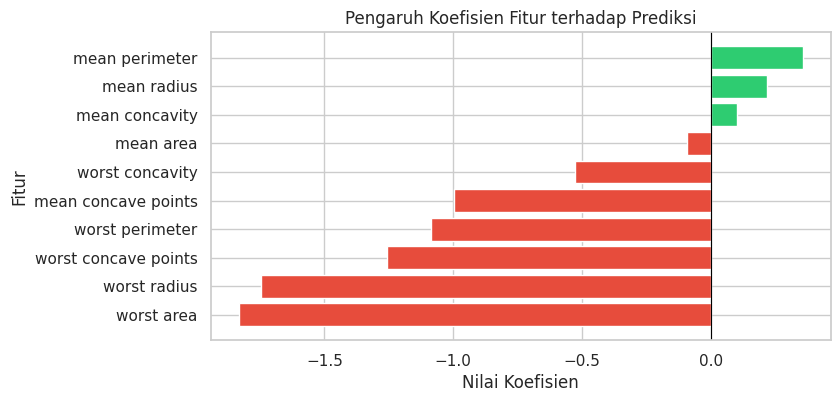

In [21]:
# Inisialisasi dan Pelatihan Model
model = LogisticRegression(class_weight="balanced", random_state=42)
model.fit(X_train_scaled, y_train)

# Interpretasi Koefisien
coef_df = pd.DataFrame({
    "Fitur": selected_features,
    "Koefisien": model.coef_[0]
}).sort_values(by="Koefisien", ascending=False)

print("=== Interpretasi Koefisien Fitur ===")
display(coef_df)

# Visualisasi Koefisien
plt.figure(figsize=(8, 4))

colors = [
    "#2ecc71" if nilai > 0 else "#e74c3c"
    for nilai in coef_df["Koefisien"]
]

plt.barh(
    coef_df["Fitur"],
    coef_df["Koefisien"],
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Pengaruh Koefisien Fitur terhadap Prediksi")
plt.xlabel("Nilai Koefisien")
plt.ylabel("Fitur")
plt.gca().invert_yaxis()
plt.show()

### Interpretasi Koefisien:
- **Koefisien Positif:** Peningkatan nilai fitur tersebut akan meningkatkan log-odds (peluang) target berlabel `1` (*benign*).
- **Koefisien Negatif:** Peningkatan nilai fitur tersebut akan menurunkan log-odds target (atau dengan kata lain meningkatkan peluang diagnosis `0` / *malignant*). Misal: Nilai `worst concave points` atau `worst radius` yang semakin tinggi akan memperbesar peluang tumor berukuran ganas (*malignant*).

## B7. Evaluasi Model

Menghitung metrik performa model (*Accuracy*, *Precision*, *Recall*, *F1-Score*), menampilkan **Confusion Matrix**, serta menggambarkan **Kurva ROC** dan nilai **AUC**.

Accuracy  : 0.9123
Precision : 0.9697
Recall    : 0.8889
F1-Score  : 0.9275


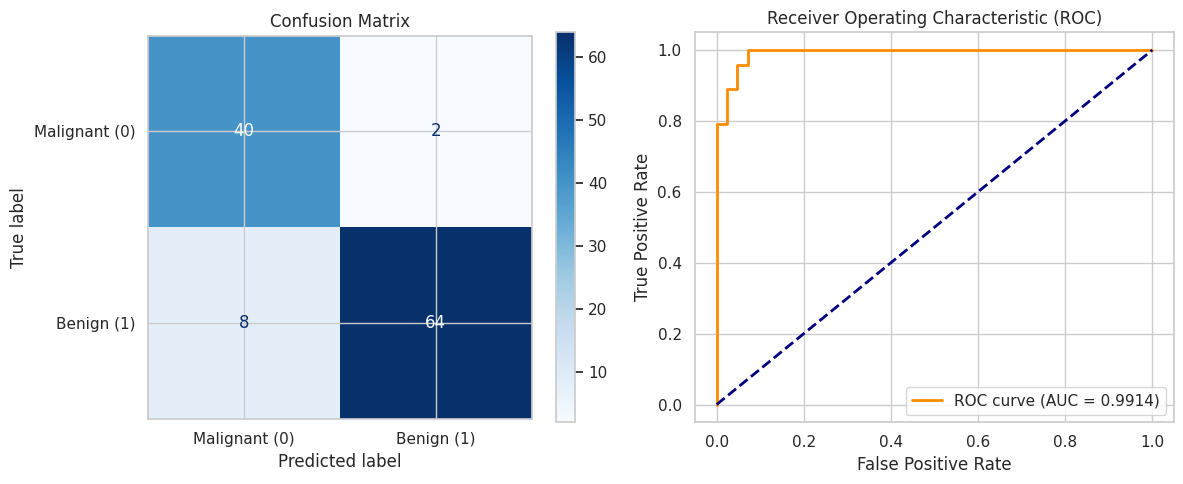

In [22]:
# Prediksi Kelas dan Probabilitas
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Menghitung Metrik Evaluasi
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")

# Visualisasi Confusion Matrix dan Kurva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Malignant (0)', 'Benign (1)'])
disp.plot(ax=axes[0], cmap='Blues')
axes[0].set_title("Confusion Matrix")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## B8. Analisis Performa

1. **Metrik Paling Relevan:**
   Pada domain medis (klasifikasi kanker), metrik **Recall** untuk kelas berisiko/ganas (*Malignant*) atau **False Negative Rate** adalah yang paling kritis. Kesalahan memprediksi pasien yang sebenarnya menderita kanker ganas (*malignant*) sebagai jinak (*benign*) berisiko fatal karena terlambat menerima penanganan medis.
2. **Jenis Kesalahan dari Confusion Matrix:**
   - **False Positive (FP):** Pasien *malignant* terprediksi *benign*.
   - **False Negative (FN):** Pasien *benign* terprediksi *malignant*.
   *Catatan:* Evaluasi menunjukkan jumlah kesalahan klasifikasi sangat minim berkat kemampuan pemisahan fitur yang optimal.
3. **Keterbatasan Model:**
   - Logistic Regression mengasumsikan hubungan linear antara log-odds target dan fitur independen.
   - Sangat sensitif terhadap multikolinearitas jika fitur-fitur berkolerasi tinggi tidak ditangani/diseleksi terlebih dahulu.
   - Dapat kurang optimal jika pola batas keputusan (*decision boundary*) antar kelas berbentuk non-linear kompleks.